# Infographix — Layout Clustering and KNN-Neighbourhood Analysis

**Purpose:** evaluate unsupervised K-means clustering of poster-layout features, compare candidate cluster counts, and add a complementary **k-nearest-neighbours (KNN) distance analysis**. Log reproducible runs and artifacts to MLflow.

> **Scientific distinction:** K-means is a clustering algorithm. KNN is usually a supervised prediction method, and `NearestNeighbors` is a neighbourhood-search method. Without independent ground-truth layout labels, they are not interchangeable models and must not be compared using the same “accuracy” metric. This notebook therefore compares K-means cluster structure with KNN-neighbourhood distances/outlier flags, without pretending that KNN produces equivalent clusters.

**Input files** (created by `02_feature_engineering.ipynb`):
- `data/processed/features/train_features.parquet`
- `data/processed/features/dev_features.parquet`
- `data/processed/features/test_features.parquet`

**Outputs:** MLflow metrics, a K-means model, KNN-neighbourhood analysis, CSV/JSON reports, cluster assignments, and plots.

Run cells from top to bottom. This notebook does not modify the source feature files or DVC data.

## 1. Imports, reproducibility, and paths

In [1]:
from pathlib import Path
import json
import warnings
import hashlib
import platform
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
)
from sklearn.neighbors import NearestNeighbors
import joblib
import mlflow
from mlflow import sklearn as mlflow_sklearn

SEED = 42
K_VALUES = list(range(2, 11))
KNN_NEIGHBORS = 10
SILHOUETTE_SAMPLE_SIZE = 3000  # limits runtime on larger training data

# Works when launched from either the repository root or notebooks/.
PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name.lower() == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

FEATURE_DIR = PROJECT_ROOT / "data" / "processed" / "features"
OUTPUT_DIR = PROJECT_ROOT / "reports" / "layout_clustering"
MODEL_DIR = PROJECT_ROOT / "models" / "layout_clustering"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

FEATURE_PATHS = {
    "train": FEATURE_DIR / "train_features.parquet",
    "dev": FEATURE_DIR / "dev_features.parquet",
    "test": FEATURE_DIR / "test_features.parquet",
}

print("Python:", sys.version.split()[0])
print("Platform:", platform.platform())
print("Project root:", PROJECT_ROOT)
print("Feature directory:", FEATURE_DIR)
for split, path in FEATURE_PATHS.items():
    print(f"{split}: {path.exists()} — {path}")

E:\Projects\infographix\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Python: 3.12.6
Platform: Windows-11-10.0.26300-SP0
Project root: E:\Projects\infographix
Feature directory: E:\Projects\infographix\data\processed\features
train: True — E:\Projects\infographix\data\processed\features\train_features.parquet
dev: True — E:\Projects\infographix\data\processed\features\dev_features.parquet
test: True — E:\Projects\infographix\data\processed\features\test_features.parquet


## 2. Confirm inputs and load feature tables

In [2]:
missing_files = [str(p) for p in FEATURE_PATHS.values() if not p.exists()]
if missing_files:
    raise FileNotFoundError(
        "Missing feature parquet file(s):\n" + "\n".join(missing_files) +
        "\nRun notebooks/02_feature_engineering.ipynb first."
    )

feature_frames = {
    split: pd.read_parquet(path)
    for split, path in FEATURE_PATHS.items()
}
for split, frame in feature_frames.items():
    print(f"\n{split}: {frame.shape}")
    display(frame.head(3))

train_raw = feature_frames["train"].copy()
dev_raw = feature_frames["dev"].copy()
test_raw = feature_frames["test"].copy()


train: (6853, 96)


,poster_id,split,aspect_ratio,pixel_width,pixel_height,element_count,element_density,sum_bbox_area_ratio,median_element_area,median_element_width,...,spread_y_table,count_unknown,proportion_unknown,area_unknown,width_unknown,height_unknown,center_x_unknown,center_y_unknown,spread_x_unknown,spread_y_unknown
0,2921933168,train,0.706838,827,1170,40,40.0,0.397554,0.005622,0.142080,...,0.0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,2541841589,train,1.285714,5400,4200,14,14.0,0.794552,0.033556,0.607959,...,0.0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,1738374677,train,0.713675,835,1170,15,15.0,0.673050,0.023426,0.414541,...,0.0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0



dev: (500, 96)


,poster_id,split,aspect_ratio,pixel_width,pixel_height,element_count,element_density,sum_bbox_area_ratio,median_element_area,median_element_width,...,spread_y_table,count_unknown,proportion_unknown,area_unknown,width_unknown,height_unknown,center_x_unknown,center_y_unknown,spread_x_unknown,spread_y_unknown
0,194056279,dev,0.963527,4174,4332,30,30.0,0.845191,0.023093,0.233364,...,0.0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,1001519623,dev,0.750000,3600,4800,26,26.0,0.782188,0.020648,0.284743,...,0.0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,1754103935,dev,0.750053,3544,4725,17,17.0,0.644712,0.011465,0.943846,...,0.0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0



test: (500, 96)


,poster_id,split,aspect_ratio,pixel_width,pixel_height,element_count,element_density,sum_bbox_area_ratio,median_element_area,median_element_width,...,spread_y_table,count_unknown,proportion_unknown,area_unknown,width_unknown,height_unknown,center_x_unknown,center_y_unknown,spread_x_unknown,spread_y_unknown
0,1869892916,test,1.277778,4600,3600,38,38.0,0.561148,0.010245,0.164915,...,0.0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,3041709520,test,1.376536,3473,2523,26,26.0,0.542287,0.020336,0.244655,...,0.0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,2606655865,test,0.707479,3311,4680,30,30.0,0.648673,0.021525,0.239839,...,0.0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## 3. Identify feature columns safely
We exclude identifiers and split metadata. Numeric feature columns are selected from the training table, and the same columns are used for dev/test. Any missing values are imputed and features are standardized using training data only. This avoids fitting preprocessing on dev/test data.

In [3]:
EXCLUDED_COLUMNS = {
    "poster_id", "image_id", "id", "file_name", "filename",
    "split", "pixel_width", "pixel_height", "width", "height",
    "image_width", "image_height",
}
# Numeric candidates from train only; identifiers are excluded by name.
candidate_columns = [
    c for c in train_raw.columns
    if c not in EXCLUDED_COLUMNS and pd.api.types.is_numeric_dtype(train_raw[c])
]
if not candidate_columns:
    raise ValueError("No numeric feature columns found in the training parquet.")

# Drop columns that are entirely missing or constant in train.
feature_columns = []
dropped_columns = {}
for col in candidate_columns:
    values = pd.to_numeric(train_raw[col], errors="coerce").replace([np.inf, -np.inf], np.nan)
    if values.notna().sum() == 0:
        dropped_columns[col] = "all_missing_in_train"
    elif values.nunique(dropna=True) <= 1:
        dropped_columns[col] = "constant_in_train"
    else:
        feature_columns.append(col)

if len(feature_columns) < 2:
    raise ValueError(f"Need at least two usable features; found {len(feature_columns)}.")

print("Numeric candidates:", len(candidate_columns))
print("Features retained:", len(feature_columns))
print("Features dropped:", len(dropped_columns))
print("First retained columns:", feature_columns[:15])

def numeric_matrix(frame, columns):
    out = frame.reindex(columns=columns).copy()
    for col in columns:
        out[col] = pd.to_numeric(out[col], errors="coerce")
    out = out.replace([np.inf, -np.inf], np.nan)
    return out

X_train_raw = numeric_matrix(train_raw, feature_columns)
X_dev_raw = numeric_matrix(dev_raw, feature_columns)
X_test_raw = numeric_matrix(test_raw, feature_columns)

imputer = SimpleImputer(strategy="median")
scaler = StandardScaler()

X_train_imputed = imputer.fit_transform(X_train_raw)
X_dev_imputed = imputer.transform(X_dev_raw)
X_test_imputed = imputer.transform(X_test_raw)

X_train = scaler.fit_transform(X_train_imputed).astype(np.float32)
X_dev = scaler.transform(X_dev_imputed).astype(np.float32)
X_test = scaler.transform(X_test_imputed).astype(np.float32)

if not (np.isfinite(X_train).all() and np.isfinite(X_dev).all() and np.isfinite(X_test).all()):
    raise ValueError("Non-finite values remain after preprocessing.")

print("Scaled shapes:", X_train.shape, X_dev.shape, X_test.shape)
print("Preprocessing fitted on train only.")

Numeric candidates: 92
Features retained: 92
Features dropped: 0
First retained columns: ['aspect_ratio', 'element_count', 'element_density', 'sum_bbox_area_ratio', 'median_element_area', 'median_element_width', 'median_element_height', 'median_center_x', 'median_center_y', 'spread_center_x', 'spread_center_y', 'count_author_info', 'proportion_author_info', 'area_author_info', 'width_author_info']
Scaled shapes: (6853, 92) (500, 92) (500, 92)
Preprocessing fitted on train only.


## 4. Define evaluation helpers
Silhouette, Davies–Bouldin, and Calinski–Harabasz describe geometric cluster structure; they are not object-detection accuracy metrics. Silhouette is sampled on large datasets to keep execution practical.

In [4]:
def cluster_metrics(X, labels, seed=SEED):
    labels = np.asarray(labels)
    unique_labels = np.unique(labels)
    n_samples = len(labels)
    n_clusters = len(unique_labels)
    result = {
        "clusters_present": int(n_clusters),
        "smallest_cluster_size": int(pd.Series(labels).value_counts().min()),
        "largest_cluster_size": int(pd.Series(labels).value_counts().max()),
    }
    if n_clusters < 2 or n_clusters >= n_samples:
        result.update({
            "silhouette": np.nan,
            "davies_bouldin": np.nan,
            "calinski_harabasz": np.nan,
        })
        return result

    sample_size = min(SILHOUETTE_SAMPLE_SIZE, n_samples)
    result["silhouette"] = float(silhouette_score(
        X, labels, sample_size=sample_size if sample_size < n_samples else None,
        random_state=seed
    ))
    result["davies_bouldin"] = float(davies_bouldin_score(X, labels))
    result["calinski_harabasz"] = float(calinski_harabasz_score(X, labels))
    return result

def safe_float(value):
    return float(value) if np.isfinite(value) else None

## 5. K-means search on train; evaluate selected candidates on dev/test
We search cluster counts on the training split. The notebook selects a candidate using the **training silhouette score** as a transparent baseline, then reports dev/test metrics for that candidate. Review cluster sizes and all metrics before treating it as a useful layout taxonomy.

In [5]:
search_rows = []
kmeans_models = {}

for k in K_VALUES:
    if k >= len(X_train):
        continue
    model = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=20,
        random_state=SEED,
        algorithm="lloyd",
    )
    train_labels = model.fit_predict(X_train)
    metrics = cluster_metrics(X_train, train_labels)
    row = {
        "k": k,
        "train_inertia": float(model.inertia_),
        **{f"train_{key}": value for key, value in metrics.items()},
    }
    search_rows.append(row)
    kmeans_models[k] = model

search_df = pd.DataFrame(search_rows)
if search_df.empty:
    raise ValueError("No K-means candidates were evaluated.")
display(search_df)

# Baseline selection: highest train silhouette; avoid invalid scores.
valid = search_df[np.isfinite(search_df["train_silhouette"])]
if valid.empty:
    raise ValueError("No candidate produced a valid training silhouette score.")
selected_k = int(valid.sort_values("train_silhouette", ascending=False).iloc[0]["k"])
selected_kmeans = kmeans_models[selected_k]
print("Selected candidate by training silhouette:", selected_k)

,k,train_inertia,train_clusters_present,train_smallest_cluster_size,train_largest_cluster_size,train_silhouette,train_davies_bouldin,train_calinski_harabasz
0,2,587087.56250,2,3024,3829,0.084397,3.188965,506.321042
1,3,554635.87500,3,5,3824,0.086747,2.455093,468.329656
2,4,527085.62500,4,6,2768,0.070250,2.455576,447.822003
3,5,507070.87500,5,6,2245,0.060184,2.447070,416.646754
4,6,496017.06250,6,6,2202,0.064892,2.341821,371.212857
5,7,486080.06250,7,5,1797,0.058696,2.512974,338.947624
6,8,474074.15625,8,1,2189,0.062112,2.045593,322.605348
7,9,462405.34375,9,2,1422,0.063592,2.313395,310.949143
8,10,453013.46875,10,1,1396,0.056974,2.116227,297.851459


Selected candidate by training silhouette: 3


## 6. Evaluate the selected K-means model on train/dev/test

In [6]:
split_arrays = {"train": X_train, "dev": X_dev, "test": X_test}
split_frames = {"train": train_raw, "dev": dev_raw, "test": test_raw}
split_metrics = {}
assignment_frames = {}

for split, X in split_arrays.items():
    labels = selected_kmeans.predict(X)
    metrics = cluster_metrics(X, labels)
    metrics["inertia_to_train_centers"] = float(
        np.sum((X - selected_kmeans.cluster_centers_[labels]) ** 2)
    )
    split_metrics[split] = metrics

    frame = split_frames[split].copy()
    frame["kmeans_cluster"] = labels
    assignment_frames[split] = frame

evaluation_df = pd.DataFrame([
    {"split": split, **metrics}
    for split, metrics in split_metrics.items()
])
display(evaluation_df)
print("Cluster counts by split:")
for split, frame in assignment_frames.items():
    print(f"\n{split}\n{frame['kmeans_cluster'].value_counts().sort_index()}")

,split,clusters_present,smallest_cluster_size,largest_cluster_size,silhouette,davies_bouldin,calinski_harabasz,inertia_to_train_centers
0,train,3,5,3824,0.086747,2.455093,468.329656,554635.875000
1,dev,3,2,262,0.085265,2.371137,81.401218,42556.445312
2,test,3,1,264,0.088291,2.131161,86.286566,39927.007812


Cluster counts by split:

train
kmeans_cluster
0    3824
1    3024
2       5
Name: count, dtype: int64

dev
kmeans_cluster
0    262
1    236
2      2
Name: count, dtype: int64

test
kmeans_cluster
0    264
1    235
2      1
Name: count, dtype: int64


## 7. KNN-neighbourhood comparison (complementary analysis, not a competing clusterer)
For each poster, compute the mean distance to its nearest neighbours in the **training feature space**. A larger distance indicates a more isolated point relative to the training data. We report dev/test distance distributions and flag the top 5% of training neighbour distances as an illustrative outlier threshold. This does not create KNN classes or prove that a poster is bad.

In [7]:
n_neighbors = min(KNN_NEIGHBORS, max(1, len(X_train) - 1))
knn = NearestNeighbors(n_neighbors=n_neighbors + 1, metric="euclidean", algorithm="auto")
knn.fit(X_train)

# For training, first neighbour is generally the point itself; remove it.
train_distances_all, _ = knn.kneighbors(X_train)
train_knn_mean_distance = train_distances_all[:, 1:].mean(axis=1)

dev_knn = NearestNeighbors(n_neighbors=n_neighbors, metric="euclidean")
dev_knn.fit(X_train)
dev_distances, _ = dev_knn.kneighbors(X_dev)
dev_knn_mean_distance = dev_distances.mean(axis=1)

test_distances, _ = dev_knn.kneighbors(X_test)
test_knn_mean_distance = test_distances.mean(axis=1)

knn_threshold = float(np.quantile(train_knn_mean_distance, 0.95))
knn_results = {
    "train": train_knn_mean_distance,
    "dev": dev_knn_mean_distance,
    "test": test_knn_mean_distance,
}
knn_summary_rows = []
for split, distances in knn_results.items():
    knn_summary_rows.append({
        "split": split,
        "k_neighbors": n_neighbors,
        "mean_neighbor_distance": float(np.mean(distances)),
        "median_neighbor_distance": float(np.median(distances)),
        "p95_neighbor_distance": float(np.quantile(distances, 0.95)),
        "outlier_threshold_from_train_p95": knn_threshold,
        "fraction_above_train_threshold": float(np.mean(distances > knn_threshold)),
    })
knn_summary_df = pd.DataFrame(knn_summary_rows)
display(knn_summary_df)

# Attach neighbourhood scores to the assignment tables.
for split, distances in knn_results.items():
    assignment_frames[split]["knn_mean_neighbor_distance"] = distances
    assignment_frames[split]["knn_is_isolated_top5pct_train_threshold"] = distances > knn_threshold

print("Interpretation: KNN scores describe local isolation, not cluster correctness.")

,split,k_neighbors,mean_neighbor_distance,median_neighbor_distance,p95_neighbor_distance,outlier_threshold_from_train_p95,fraction_above_train_threshold
0,train,10,6.464422,6.042661,8.838673,8.838673,0.050051
1,dev,10,6.670018,6.061844,9.337304,8.838673,0.062000
2,test,10,6.421675,6.001908,8.703660,8.838673,0.044000


Interpretation: KNN scores describe local isolation, not cluster correctness.


## 8. Visualize K-means search and KNN distances

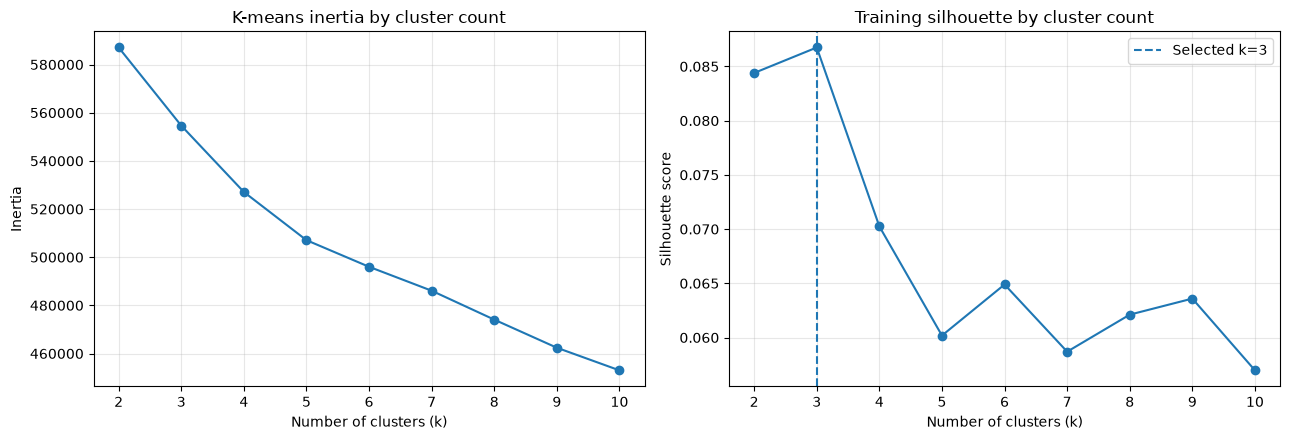

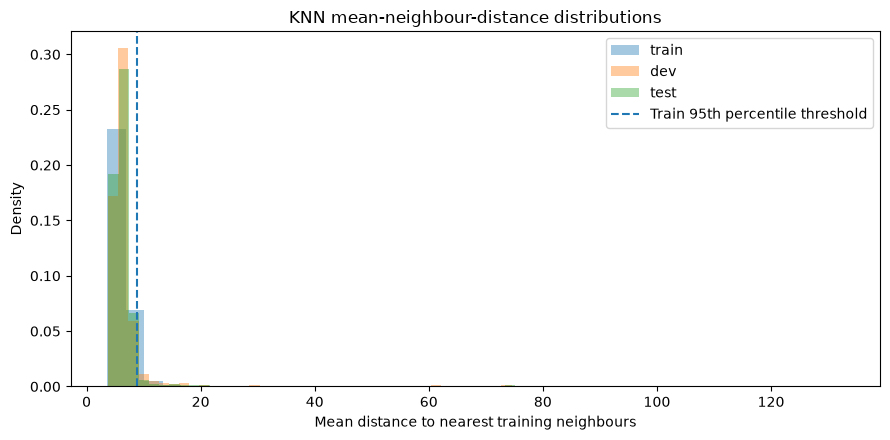

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(search_df["k"], search_df["train_inertia"], marker="o")
axes[0].set_title("K-means inertia by cluster count")
axes[0].set_xlabel("Number of clusters (k)")
axes[0].set_ylabel("Inertia")
axes[0].grid(True, alpha=0.3)

axes[1].plot(search_df["k"], search_df["train_silhouette"], marker="o")
axes[1].axvline(selected_k, linestyle="--", label=f"Selected k={selected_k}")
axes[1].set_title("Training silhouette by cluster count")
axes[1].set_xlabel("Number of clusters (k)")
axes[1].set_ylabel("Silhouette score")
axes[1].legend()
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 4.5))
for split, distances in knn_results.items():
    plt.hist(distances, bins=40, alpha=0.4, label=split, density=True)
plt.axvline(knn_threshold, linestyle="--", label="Train 95th percentile threshold")
plt.title("KNN mean-neighbour-distance distributions")
plt.xlabel("Mean distance to nearest training neighbours")
plt.ylabel("Density")
plt.legend()
plt.tight_layout()
plt.show()

## 9. Persist reports, assignments, preprocessing, and model

In [9]:
search_csv = OUTPUT_DIR / "kmeans_search_results.csv"
evaluation_json = OUTPUT_DIR / "kmeans_evaluation_report.json"
knn_csv = OUTPUT_DIR / "knn_neighborhood_summary.csv"
model_path = MODEL_DIR / f"kmeans_k{selected_k}.joblib"
preprocessor_path = MODEL_DIR / "feature_preprocessor.joblib"

search_df.to_csv(search_csv, index=False)
knn_summary_df.to_csv(knn_csv, index=False)

report = {
    "project": "infographix",
    "experiment": "infographix-baseline",
    "selected_k": selected_k,
    "selection_rule": "highest training silhouette among tested k values",
    "seed": SEED,
    "k_values_tested": K_VALUES,
    "n_features": len(feature_columns),
    "feature_columns": feature_columns,
    "dropped_columns": dropped_columns,
    "split_rows": {split: int(len(frame)) for split, frame in split_frames.items()},
    "kmeans_metrics": {
        split: {key: safe_float(value) if isinstance(value, (int, float, np.number)) else value
                for key, value in metrics.items()}
        for split, metrics in split_metrics.items()
    },
    "knn_neighborhood": {
        "n_neighbors": n_neighbors,
        "threshold_quantile": 0.95,
        "threshold_from_train": knn_threshold,
        "summary": knn_summary_df.to_dict(orient="records"),
        "interpretation": "Neighbourhood isolation analysis, not a supervised KNN classifier or clustering algorithm."
    },
}
evaluation_json.write_text(json.dumps(report, indent=2, allow_nan=False), encoding="utf-8")

for split, frame in assignment_frames.items():
    frame.to_csv(OUTPUT_DIR / f"{split}_cluster_assignments.csv", index=False)

joblib.dump({
    "model": selected_kmeans,
    "feature_columns": feature_columns,
    "imputer": imputer,
    "scaler": scaler,
    "selected_k": selected_k,
    "seed": SEED,
}, model_path)
joblib.dump({
    "feature_columns": feature_columns,
    "imputer": imputer,
    "scaler": scaler,
}, preprocessor_path)

print("Saved:")
for path in [search_csv, evaluation_json, knn_csv, model_path, preprocessor_path]:
    print(path)

Saved:
E:\Projects\infographix\reports\layout_clustering\kmeans_search_results.csv
E:\Projects\infographix\reports\layout_clustering\kmeans_evaluation_report.json
E:\Projects\infographix\reports\layout_clustering\knn_neighborhood_summary.csv
E:\Projects\infographix\models\layout_clustering\kmeans_k3.joblib
E:\Projects\infographix\models\layout_clustering\feature_preprocessor.joblib


## 10. Log reproducible experiments to MLflow
The notebook logs a parent run with the selected model, metrics, and artifacts, plus one child run per tested K-means cluster count. KNN is logged separately as a neighbourhood-distance analysis. Existing runs are preserved.

In [10]:
TRACKING_URI = "sqlite:///" + (PROJECT_ROOT / "mlflow.db").as_posix().lstrip("/")
# Windows absolute paths need sqlite:///E:/...; construct explicitly for portability.
TRACKING_URI = f"sqlite:///{(PROJECT_ROOT / 'mlflow.db').as_posix()}"
mlflow.set_tracking_uri(TRACKING_URI)
mlflow.set_experiment("infographix-baseline")

with mlflow.start_run(run_name=f"layout-clustering-selected-k{selected_k}") as parent_run:
    mlflow.set_tags({
        "project": "infographix",
        "task": "unsupervised-poster-layout-analysis",
        "selected_algorithm": "KMeans",
        "knn_role": "neighborhood-distance-analysis",
    })
    mlflow.log_params({
        "selected_k": selected_k,
        "k_values_tested": ",".join(map(str, K_VALUES)),
        "seed": SEED,
        "n_features": len(feature_columns),
        "knn_neighbors": n_neighbors,
        "knn_threshold_quantile": 0.95,
        "selection_rule": "highest_train_silhouette",
    })

    for _, row in search_df.iterrows():
        k = int(row["k"])
        with mlflow.start_run(run_name=f"kmeans-search-k{k}", nested=True):
            mlflow.log_param("algorithm", "KMeans")
            mlflow.log_param("k", k)
            mlflow.log_param("seed", SEED)
            for col, value in row.items():
                if col != "k" and pd.notna(value) and isinstance(value, (int, float, np.number)):
                    mlflow.log_metric(col, float(value))

    for split, metrics in split_metrics.items():
        for name, value in metrics.items():
            if isinstance(value, (int, float, np.number)) and np.isfinite(value):
                mlflow.log_metric(f"{split}_{name}", float(value))

    for _, row in knn_summary_df.iterrows():
        split = row["split"]
        for name in [
            "mean_neighbor_distance", "median_neighbor_distance",
            "p95_neighbor_distance", "fraction_above_train_threshold"
        ]:
            mlflow.log_metric(f"knn_{split}_{name}", float(row[name]))

    mlflow.log_artifact(str(search_csv), artifact_path="evaluation")
    mlflow.log_artifact(str(evaluation_json), artifact_path="evaluation")
    mlflow.log_artifact(str(knn_csv), artifact_path="evaluation")
    for split in assignment_frames:
        mlflow.log_artifact(str(OUTPUT_DIR / f"{split}_cluster_assignments.csv"), artifact_path="assignments")
    mlflow.log_artifact(str(model_path), artifact_path="model")
    mlflow.log_artifact(str(preprocessor_path), artifact_path="model")

    # Keep a copy of the source notebook and this run's basic metadata when available.
    notebook_path = PROJECT_ROOT / "notebooks" / "03_kmeans_mlflow_evaluation.ipynb"
    if notebook_path.exists():
        mlflow.log_artifact(str(notebook_path), artifact_path="source")

print("MLflow tracking URI:", mlflow.get_tracking_uri())
print("Experiment:", "infographix-baseline")
print("Parent run ID:", parent_run.info.run_id)

MLflow tracking URI: sqlite:///E:/Projects/infographix/mlflow.db
Experiment: infographix-baseline
Parent run ID: f1ccef81d63545f4a4c0135c477a5f66


## 11. Final summary and scientific cautions

In [11]:
print(f"Selected K-means k: {selected_k}")
print("\nK-means split metrics:")
display(evaluation_df)
print("\nKNN neighbourhood summary:")
display(knn_summary_df)

print("\nArtifacts directory:", OUTPUT_DIR)
print("Model directory:", MODEL_DIR)
print("MLflow tracking URI:", mlflow.get_tracking_uri())

print(
    "\nCaution: selection by training silhouette is a baseline heuristic, not proof of a "
    "semantically correct taxonomy. Inspect cluster sizes, sample posters per cluster, "
    "dev/test stability, and domain usefulness before adopting a final model. "
    "KNN distances are an isolation signal and are not directly comparable to K-means scores."
)

Selected K-means k: 3

K-means split metrics:


,split,clusters_present,smallest_cluster_size,largest_cluster_size,silhouette,davies_bouldin,calinski_harabasz,inertia_to_train_centers
0,train,3,5,3824,0.086747,2.455093,468.329656,554635.875000
1,dev,3,2,262,0.085265,2.371137,81.401218,42556.445312
2,test,3,1,264,0.088291,2.131161,86.286566,39927.007812



KNN neighbourhood summary:


,split,k_neighbors,mean_neighbor_distance,median_neighbor_distance,p95_neighbor_distance,outlier_threshold_from_train_p95,fraction_above_train_threshold
0,train,10,6.464422,6.042661,8.838673,8.838673,0.050051
1,dev,10,6.670018,6.061844,9.337304,8.838673,0.062000
2,test,10,6.421675,6.001908,8.703660,8.838673,0.044000



Artifacts directory: E:\Projects\infographix\reports\layout_clustering
Model directory: E:\Projects\infographix\models\layout_clustering
MLflow tracking URI: sqlite:///E:/Projects/infographix/mlflow.db

Caution: selection by training silhouette is a baseline heuristic, not proof of a semantically correct taxonomy. Inspect cluster sizes, sample posters per cluster, dev/test stability, and domain usefulness before adopting a final model. KNN distances are an isolation signal and are not directly comparable to K-means scores.


## How to interpret and continue

1. Compare K-means candidate rows in `kmeans_search_results.csv`; don't select only by inertia.
2. Inspect `train_cluster_assignments.csv`, `dev_cluster_assignments.csv`, and `test_cluster_assignments.csv` alongside poster examples to understand what each cluster represents.
3. Inspect `knn_neighborhood_summary.csv` for unusually isolated layouts. Treat the 95th-percentile threshold as exploratory, not a validated anomaly detector.
4. In MLflow, open the `infographix-baseline` experiment and find the run named `layout-clustering-selected-k...`. The run contains metrics and artifacts.
5. If the goal later becomes predicting a known human-defined layout category, obtain independent ground-truth labels first. Then a true supervised KNN classifier can be evaluated against a suitable baseline using held-out labels.

**Runtime:** on the order of minutes, depending on machine and data size. The silhouette calculation is sampled for larger splits to limit runtime. No code in this notebook modifies the original parquet inputs.